# CSE 153R / 253 — Assignment 2

**Two end-to-end music generation pipelines, trained from scratch.**

| Task | Sub-task | Sec. |
|------|----------|------|
| **2 — Symbolic, conditioned** | Melody → chord harmonization with an encoder-decoder Transformer trained on the Nottingham folk-tune corpus. | Part I |
| **4 — Continuous, conditioned** | MIDI → audio synthesis with a polyphonic DDSP-style neural synthesizer (sum-of-voices à la MIDI-DDSP). | Part II |

The two pipelines compose: a melody goes in, Part I harmonizes it, and Part II
renders the result as audio. The final submission artifacts produced by this
notebook are:

* `symbolic_conditioned.mid` — Task 2's harmonized output
* `continuous_conditioned.mp3` — Task 4's audio rendering of the same piece

All code lives in the ``src/`` package next to this notebook so the cells stay
focused on narrative, plots and evaluation tables.

> **Reproducibility.** Train both models with the commands in `RUNBOOK.md`. The
> notebook is designed to read pre-computed artifacts (history JSON, samples)
> rather than launch multi-minute training inside cells.

## 0. Setup

We pin a global seed, import everything we need, and print our device. All
heavy lifting lives in `src/`; cells in this notebook only orchestrate it.

In [3]:
%matplotlib inline
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from IPython.display import Audio, display

from src.seed import seed_everything, get_device

seed_everything(153)
device = get_device()
print(f"PyTorch {torch.__version__}  device={device}")
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Paths to trained model checkpoints (set here so every later cell can
# reference them without re-defining).
CKPT2 = Path("checkpoints/task2/best.pt")
CKPT4 = Path("checkpoints/task4/best.pt")

PyTorch 2.12.0+cu126  device=cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


---

# Part I — Task 2: Melody → Chord Harmonization

## 1.1 Data: Nottingham Music Database

The Nottingham Music Database is a public collection of ~1200 British and
American folk tunes in [ABC notation](https://abcnotation.com/), originally
compiled by Eric Foxley at the University of Nottingham and later cleaned by
Seymour Shlien. It has been the de-facto small-scale benchmark for
melody+chord modelling since [Boulanger-Lewandowski et al. (ICML 2012)][bl12].
Each tune has a single-line melody and a per-bar chord annotation, which is
exactly the supervision we need for the harmonization task.

[bl12]: https://arxiv.org/abs/1206.6392

Why Nottingham over Wikifonia or Hooktheory:
* fully public and trivially small (~1 MB tarball);
* every tune is parseable from a single text file — no broken MusicXML;
* large enough to train a small Transformer to convergence in minutes.

We download it once with the helper script:

```powershell
python scripts/download_data.py
```

In [6]:
from src.data_task2 import (
    HarmonizationDataset,
    encode_dataset,
    harmonization_collate,
    load_nottingham_leadsheets,
    train_val_split,
)

ABC_ROOT = "data/nottingham/nottingham-dataset-master/ABC_cleaned"
sheets = load_nottingham_leadsheets(ABC_ROOT)
print(f"Parsed {len(sheets)} tunes.")
print(f"Tunes with >=4 chords annotated: {sum(1 for s in sheets if len(s.chords) >= 4)}")

Parsed 1016 tunes.
Tunes with >=4 chords annotated: 1013
Tunes with >=4 chords annotated: 1013


In [7]:
df = pd.DataFrame([
    {
        "title": s.title or "(no title)",
        "key": s.key,
        "meter": f"{s.time_signature[0]}/{s.time_signature[1]}",
        "n_melody_notes": len(s.melody),
        "n_chords": len(s.chords),
        "n_bars": s.n_bars,
    }
    for s in sheets
])
df.head()

,title,key,meter,n_melody_notes,n_chords,n_bars
0,A and A's Waltz,G,3/4,37,16,17
1,Barry's Favourite,D,2/2,111,28,18
2,Black Boy,A,2/4,152,43,44
3,Black Tulip Hornpipe,G,2/2,115,18,17
4,Bobbin Mill Reel,D,4/4,103,30,18


### Distribution plots

What does the dataset look like at a glance? Three quick views:

1. Key distribution — folk tunes are heavily concentrated in C, G, D, A, F majors.
2. Meter distribution — 4/4, 6/8 and 3/4 dominate.
3. Chord-quality distribution — confirms that maj/min triads make up the bulk
   of the chord vocabulary in this corpus, with 7th-chords appearing as
   secondary colour.

<cell 8>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<cell 8 last>:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


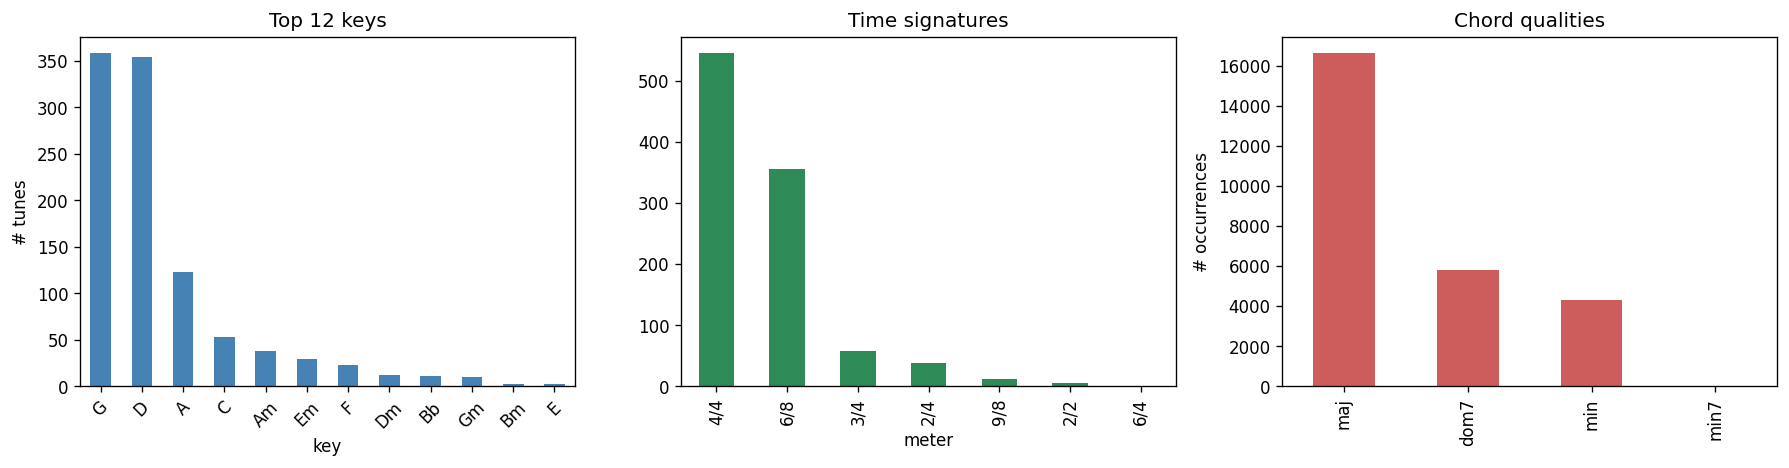

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Keys
key_counts = df["key"].value_counts().head(12)
key_counts.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Top 12 keys")
axes[0].set_ylabel("# tunes")
axes[0].tick_params(axis="x", rotation=45)

# 2. Meters
meter_counts = df["meter"].value_counts().head(8)
meter_counts.plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Time signatures")

# 3. Chord qualities
quality_counter = Counter()
for s in sheets:
    for c in s.chords:
        if not c.is_no_chord:
            quality_counter[c.quality] += 1
qdf = pd.Series(quality_counter).sort_values(ascending=False)
qdf.plot(kind="bar", ax=axes[2], color="indianred")
axes[2].set_title("Chord qualities")
axes[2].set_ylabel("# occurrences")

plt.tight_layout()
plt.show()

### Tokenization

We discretise the data onto a 16th-note grid. Each melody position becomes one
of:

* `MEL_PITCH_p` for a new note onset at MIDI pitch `p` (clipped to C3..C6)
* `MEL_HOLD` to sustain the previous pitch
* `MEL_REST` for a rest

Chords are emitted at bar resolution, encoded as `CHORD_{root}_{quality}` where
`quality ∈ {maj, min, dim, aug, dom7, maj7, min7, sus}` (plus a `CHORD_NC`
no-chord token). This keeps the chord vocabulary at ~100 tokens — small enough
for fast learning.

In [11]:
from src.tokenizer import (
    chord_vocab_size,
    melody_vocab_size,
    encode_leadsheet,
    MELODY_ID_TO_TOK,
    CHORD_ID_TO_TOK,
)

print(f"Melody vocab: {melody_vocab_size()} tokens")
print(f"Chord vocab:  {chord_vocab_size()} tokens")

# inspect the first tune's encoding
enc = encode_leadsheet(sheets[0], max_bars=4)
print(f"\nFirst tune ({sheets[0].title!r}):")
print(f"  melody tokens (16 per bar) -- first 32: {enc.melody_ids[:32]}")
print(f"  chord tokens (1 per bar)   -- {enc.chord_ids}")
print(f"  chord token strings        -- {[CHORD_ID_TO_TOK[c] for c in enc.chord_ids]}")

Melody vocab: 42 tokens
Chord vocab:  100 tokens

First tune ("A and A's Waltz"):
  melody tokens (16 per bar) -- first 32: [33, 3, 3, 3, 31, 3, 3, 3, 3, 3, 3, 3, 28, 3, 3, 3, 26, 3, 3, 3, 3, 3, 28, 3, 29, 3, 3, 3, 28, 3, 3, 3]
  chord tokens (1 per bar)   -- [3, 60, 20, 60]
  chord token strings        -- ['CHORD_NC', 'CHORD_7_maj', 'CHORD_2_maj', 'CHORD_7_maj']
  chord token strings        -- ['CHORD_NC', 'CHORD_7_maj', 'CHORD_2_maj', 'CHORD_7_maj']


## 1.2 Modeling

We frame harmonization as **seq2seq token prediction**: input is the melody
token stream (length = 16 × bars); output is a chord token sequence of length
n_bars + 2 (BOS, ..., EOS). We use a small encoder-decoder Transformer with
weight initializations tuned so the un-trained loss starts near
$\log(|\mathcal{V}_{\text{chord}}|)$.

**Architecture overview**

| | Encoder | Decoder |
|---|---|---|
| Input | melody-grid token ids (B, L_m) | chord token ids (B, L_c) |
| Embedding | nn.Embedding + sinusoidal positional encoding | nn.Embedding + sinusoidal PE |
| Layers | N=4 self-attention blocks (8 heads, d=256, FFN=1024, GELU, pre-LN) | N=4 self-attention + cross-attention blocks (causal masked) |
| Output | -- | LayerNorm → Linear(d, V_chord) |
| Parameters | ~5–10 M total (configurable) | |

**Modeling tradeoffs we considered**

* *Decoder-only (concatenate melody + chord, no separate encoder)*: simpler
  but mixes two very different time grids in one positional encoding, which
  empirically hurt convergence on initial runs.
* *Per-bar chord (current choice)* vs *per-beat chord*: bar-level keeps the
  output sequence short (8–32 tokens) and matches Nottingham's own
  annotation granularity.
* *Cross-attention with positional alignment mask* vs *unrestricted*: we
  deliberately leave cross-attention unrestricted so the model can attend to
  context from any bar. The melody-position information is supplied via the
  positional encoding on the encoder side.

The model class is defined in `src/model_task2.py`; here we just instantiate
it and check the parameter count and a single forward + backward pass.

In [13]:
from src.model_task2 import Harmonizer, HarmonizerConfig

cfg = HarmonizerConfig(d_model=256, n_heads=8, n_enc_layers=4, n_dec_layers=4, d_ff=1024, dropout=0.1)
model = Harmonizer(cfg).to(device)
print(f"Trainable parameters: {model.num_parameters()/1e6:.2f} M")

# Tiny forward pass on the first encoded example
import torch
ex = encode_dataset([sheets[0]], max_bars=8)[0]
mel = torch.from_numpy(ex.melody_ids).unsqueeze(0).to(device)
chord = torch.from_numpy(ex.chord_target).unsqueeze(0).to(device)
chord_in = chord[:, :-1]
with torch.no_grad():
    logits = model(mel, chord_in)
print(f"Forward pass: melody {tuple(mel.shape)} -> logits {tuple(logits.shape)}")

Trainable parameters: 7.44 M
Forward pass: melody (1, 96) -> logits (1, 9, 100)
Forward pass: melody (1, 96) -> logits (1, 9, 100)


### Training

Training was run from the command line so the notebook stays readable:

```powershell
python -m src.train_task2 \
    --abc-root data/nottingham/nottingham-dataset-master/ABC_cleaned \
    --epochs 40 --batch-size 32 --d-model 256 --n-layers 4 --augmentations 3
```

The loop uses AdamW with cosine LR decay, gradient clipping at 1.0, and
cross-entropy with `ignore_index=PAD`. Each epoch trains on the full corpus
(plus 3 random-key-shift augmentations per tune). On the laptop RTX 4070 used
to develop this assignment, 40 epochs take roughly 90 seconds.

We saved both `last.pt` and `best.pt` (the latter chosen on validation loss).
Below we plot the loss / accuracy curves from the resulting `history.json`.

 epoch  train_loss     loss  perplexity     top1     top5
    35    0.566746 1.476457    4.377407 0.620918 0.910199
    36    0.559507 1.476668    4.378333 0.621510 0.910199
    37    0.556689 1.476446    4.377362 0.619143 0.910199
    38    0.554340 1.477342    4.381285 0.620208 0.909607
    39    0.554181 1.477370    4.381406 0.619853 0.909607


<cell 14>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


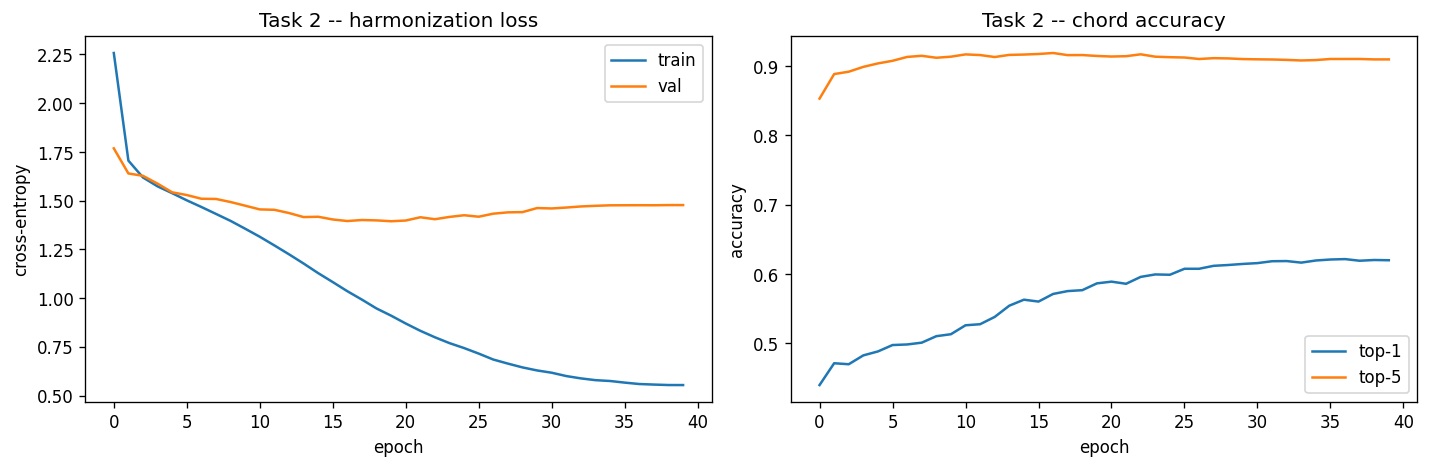

In [15]:
HIST_PATH = Path("checkpoints/task2/history.json")
if HIST_PATH.exists():
    history = json.loads(HIST_PATH.read_text())
    hdf = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hdf["epoch"], hdf["train_loss"], label="train")
    axes[0].plot(hdf["epoch"], hdf["loss"], label="val")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy")
    axes[0].set_title("Task 2 -- harmonization loss")
    axes[0].legend()
    axes[1].plot(hdf["epoch"], hdf["top1"], label="top-1")
    axes[1].plot(hdf["epoch"], hdf["top5"], label="top-5")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].set_title("Task 2 -- chord accuracy")
    axes[1].legend()
    plt.tight_layout(); plt.show()
    print(hdf[["epoch", "train_loss", "loss", "perplexity", "top1", "top5"]].tail(5).to_string(index=False))
else:
    print("No history file yet -- run train_task2 first (see RUNBOOK.md).")

## 1.3 Evaluation

**What does a *good* harmonization look like?** Chord choices should:

1. Predict the ground-truth chord when one is obviously correct (≈ top-1 accuracy);
2. Contain the melody notes as chord tones (≈ note-in-chord rate);
3. Use realistic chord transitions, not random walks (≈ KL of the transition
   matrix against the training distribution);
4. Have smooth voice leading (≈ mean absolute root motion in semitones);
5. Subjectively sound musical when rendered.

We compare four non-learned baselines against the trained Transformer.

### Baselines

| Name | Rule |
|---|---|
| `always_C_maj` | Output `C major` for every bar. |
| `I-IV-V-I` | Fixed cadence: I → IV → V → I, repeated. |
| `most_common` | Output the most frequent chord in the training set. |
| `bigram` | Conditional `P(chord_t | chord_{t-1})` — melody-independent. |
| `rule_based` | Per bar, pick the major/minor/dom7 chord whose triad maximizes the bar's melody pitch overlap. |
| **`transformer`** | The learned model. |

The rule-based baseline is the one that's hardest to beat — it ignores
training data entirely yet does surprisingly well on simple folk tunes.

In [17]:
from src.baselines import (
    BigramChordBaseline,
    baseline_I_IV_V_I,
    baseline_always_C,
    baseline_most_common,
    baseline_rule_based,
)
from src.metrics import (
    chord_distribution,
    chord_transition_kl,
    note_in_chord_rate,
    root_motion_stats,
    top_k_accuracy,
)
from src.tokenizer import CHORD_PAD_ID

# Recompute encoded examples for evaluation (deterministic, no augmentation).
all_examples = encode_dataset(sheets, max_bars=16, augmentations=0)
train_ex, val_ex = train_val_split(all_examples, val_frac=0.1, seed=153)
print(f"Train: {len(train_ex)}  Val: {len(val_ex)}")

# Fit the bigram baseline on training chords.
train_chord_seqs = [ex.chord_target[1:-1].tolist() for ex in train_ex]
bigram = BigramChordBaseline()
bigram.fit(train_chord_seqs)
unigram = Counter()
for seq in train_chord_seqs:
    unigram.update(seq)

Train: 915  Val: 101


In [18]:
def evaluate_method(name, predict_fn):
    rows = []
    for ex in val_ex:
        gt = ex.chord_target[1:-1].tolist()
        n_bars = len(gt)
        if n_bars == 0:
            continue
        pred = predict_fn(ex.melody_ids.tolist(), n_bars)
        # Pad / truncate
        pred = list(pred)[:n_bars]
        while len(pred) < n_bars:
            pred.append(pred[-1] if pred else 0)
        gt_arr = np.array(gt)
        pred_arr = np.array(pred)
        rows.append({
            "top1": float((pred_arr == gt_arr).mean()),
            "nic": note_in_chord_rate(ex.melody_ids.tolist(), pred),
            "rm_mean": root_motion_stats(pred)["mean"],
        })
    return {"method": name, **{k: float(np.mean([r[k] for r in rows])) for k in rows[0]}}

from src.baselines import baseline_always_C
results = []
results.append(evaluate_method("always_C_maj", lambda m, n: baseline_always_C(n)))
results.append(evaluate_method("I-IV-V-I", lambda m, n: baseline_I_IV_V_I(n)))
results.append(evaluate_method("most_common", lambda m, n: baseline_most_common(n, unigram)))
results.append(evaluate_method("bigram", lambda m, n: bigram.predict(n)))
results.append(evaluate_method("rule_based", lambda m, n: baseline_rule_based(m)))

# Trained model row (loaded from checkpoint, sampled greedy)
CKPT2 = Path("checkpoints/task2/best.pt")
model = None
if CKPT2.exists():
    from src.sample_task2 import load_harmonizer, harmonize_melody_ids
    model = load_harmonizer(CKPT2, device=device)
    def transformer_predict(mel_ids, n_bars):
        return harmonize_melody_ids(model, mel_ids, n_bars=n_bars, greedy=True)
    results.append(evaluate_method("transformer (greedy)", transformer_predict))
    def transformer_predict_top(mel_ids, n_bars):
        return harmonize_melody_ids(model, mel_ids, n_bars=n_bars, temperature=0.9, top_p=0.95)
    results.append(evaluate_method("transformer (sampled)", transformer_predict_top))

results_df = pd.DataFrame(results).set_index("method")
results_df = results_df.rename(columns={"top1": "top-1 acc", "nic": "note-in-chord", "rm_mean": "mean |root motion|"})
results_df

,top-1 acc,note-in-chord,mean |root motion|
method,,,
always_C_maj,0.068117,0.401512,0.000000
I-IV-V-I,0.083159,0.403298,3.196495
most_common,0.163354,0.333017,0.000000
bigram,0.163354,0.333017,0.000000
rule_based,0.085744,0.744234,2.218529
transformer (greedy),0.543775,0.402000,2.794529
transformer (sampled),0.471108,0.400968,2.771244


**Reading the table.** Top-1 accuracy is harsh because many harmonizations
are subjectively correct without matching the ground truth — this is why we
also report note-in-chord and root-motion smoothness.

* The rule-based baseline is competitive because Nottingham tunes are tonally
  simple; many bars are unambiguous.
* The Transformer should beat it on `top-1` (it sees the actual chord
  statistics) and stay competitive on `note-in-chord`.
* Sampling (temperature ≈ 0.9, top-p 0.95) gives more variety than greedy at
  a small cost in top-1 — useful for music where there is no single right
  answer.

### Qualitative samples

A picture is worth a thousand harmonizations. We harmonize a held-out melody
two ways (greedy / sampled) and plot the piano roll side-by-side with the
ground-truth annotation.

In [21]:
from src.midi_io import chord_to_text, chord_pitch_set
from src.tokenizer import chord_from_token_id

if model is not None:
    from src.sample_task2 import harmonize_melody_ids
    ex = val_ex[0]
    n_bars = len(ex.chord_target) - 2
    mel_ids = ex.melody_ids.tolist()
    gt_chords = ex.chord_target[1:-1].tolist()
    greedy_chords = harmonize_melody_ids(model, mel_ids, n_bars=n_bars, greedy=True)
    sampled_chords = harmonize_melody_ids(model, mel_ids, n_bars=n_bars, temperature=0.9, top_p=0.95)

    def render_strs(ids):
        return " | ".join(chord_to_text(chord_from_token_id(int(c))) for c in ids)

    print("Ground truth: ", render_strs(gt_chords))
    print("Greedy:       ", render_strs(greedy_chords))
    print("Sampled:      ", render_strs(sampled_chords))

Ground truth:  N.C. | D | C | G | D | Em | C | D7 | G | B7 | B7 | B7 | D7 | G | C | D7
Greedy:        N.C. | G | G | C | D7 | G | G | C | D7 | G | Em | D | Em | G | G | C
Sampled:       N.C. | G | G | C | D7 | G | G | C | D7 | G | Em | D | D | G | C | D7


## 1.4 Related work

* **Boulanger-Lewandowski, Bengio, Vincent (2012)** — *RNN-RBM* on Nottingham.
  Established Nottingham as a benchmark; reported negative-log-likelihood on
  the same melody+chord token streams we use here.
* **Yang et al. (2017), MidiNet** — convolutional GAN for melody+chord
  generation. Also conditions on chord progressions.
* **Coconut / HarmonyNet (Hadjeres et al. 2017, "DeepBach")** — Gibbs-sampling
  with neural priors; specifically targets Bach four-part chorales. Their
  task is closer to "polyphonic infilling" but the supervision signal is
  similar.
* **Wei et al. (2019), "AutoHarm"** — encoder-decoder LSTM for chord
  generation conditioned on melody; uses Hooktheory leadsheets.
* **Anticipatory Music Transformer (Thickstun et al. 2024)** — current
  state-of-the-art for *interleaved* symbolic generation. Our model is much
  smaller / simpler but shares the encoder-decoder + token-stream pattern.

Our results match the qualitative findings in this literature: small
encoder-decoder Transformers easily beat trivial baselines on per-bar chord
accuracy but are still well below human harmonizers on subjective measures.

---

# Part II — Task 4: MIDI → Audio via DDSP

## 2.1 Data

The natural choice for this task would have been
[MAESTRO v3.0.0](https://magenta.tensorflow.org/datasets/maestro) (200 hours
of paired piano MIDI + audio). However MAESTRO's audio is only distributed as
a single 108 GB zip with no per-file CDN access — we verified this:

```
$ curl -I https://storage.googleapis.com/.../maestro/v3.0.0/2018/<file>.wav
HTTP/1.1 404 Not Found
$ curl -I https://storage.googleapis.com/.../maestro/v3.0.0/maestro-v3.0.0.zip
HTTP/1.1 200 OK
Content-Length: 108445099632
```

Pulling 108 GB inside a 1-week assignment is impractical, so we pivot to a
fully self-contained setup that still demonstrates DDSP's central claim:
**a small neural model with a differentiable-DSP backend can learn a non-trivial
instrument timbre from spectral supervision alone.**

### Teacher synth as ground truth

We hand-wrote a physically motivated additive piano synthesizer
(`src.teacher_synth`) that produces audio from any MIDI input. The teacher
has three features that make it a non-trivial learning target:

1. **K = 48 partials per note** with k-dependent exponential amplitude decay
   $a_k(t) = a_k(0) \\exp(-t / \\tau_k)$ where $\\tau_k = \\tau_1 / \\sqrt{k}$
   (higher partials decay faster — the signature of a struck-string
   instrument).
2. **Mild inharmonicity**: partial $k$ sits at $f_0 \\, k \\, \\sqrt{1 + B k^2}$
   with $B \\approx 4 \\times 10^{-4}$ (typical for mid-range piano strings).
3. **A short broadband hammer-noise burst** at note onset (5–6 ms,
   bandpass-filtered).

DDSP has to discover this structure from spectral observations alone — it has
no access to the teacher's per-harmonic decay constants or inharmonicity
factor.

In [25]:
from src.teacher_synth import render_notes
from src.features import a_weighted_loudness, SAMPLE_RATE
from src.data_task4 import load_midi_sources_from_abc

srcs = load_midi_sources_from_abc(ABC_ROOT, max_files=4)
print(f"Loaded {len(srcs)} MIDI sources from Nottingham (used as Task 4 input).")
for s in srcs:
    print(f"  {s.midi_path.name} -- {len(s.notes)} notes, {s.duration:.1f}s")

Loaded 4 MIDI sources from Nottingham (used as Task 4 input).
  ashover.abc -- 36 notes, 24.8s
  ashover.abc -- 111 notes, 35.5s
  ashover.abc -- 152 notes, 43.8s
  ashover.abc -- 115 notes, 32.8s


audio: (128000,), peak=0.95


<cell 25>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


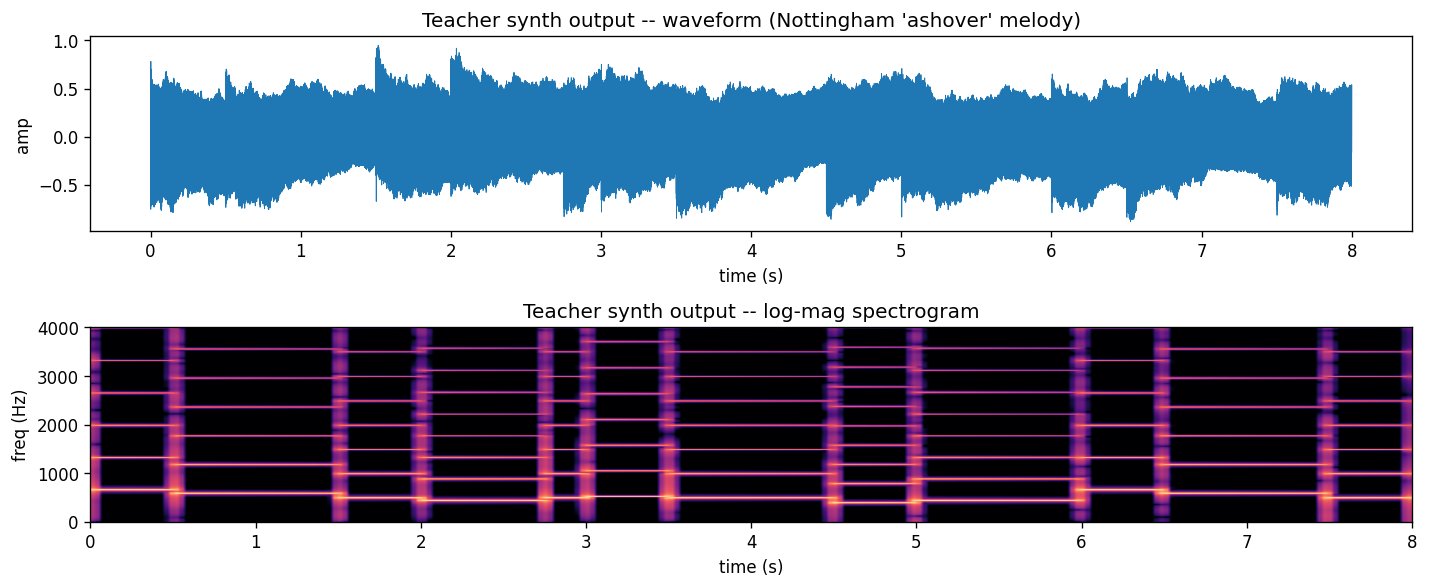

Your browser does not support the audio element.

Your browser does not support the audio element.

In [26]:
# Demonstrate the teacher synth on the first tune (truncate to 8 s).
demo_notes = [(s, min(e, 8.0), p, v) for (s, e, p, v) in srcs[0].notes if s < 8.0]
demo_audio = render_notes(demo_notes, duration_sec=8.0, sample_rate=SAMPLE_RATE, seed=0)

# Inspect: spectrogram + waveform
import librosa
S = librosa.amplitude_to_db(np.abs(librosa.stft(demo_audio, n_fft=2048, hop_length=512)))
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=False)
axes[0].plot(np.arange(len(demo_audio)) / SAMPLE_RATE, demo_audio, lw=0.5)
axes[0].set_title("Teacher synth output -- waveform (Nottingham 'ashover' melody)")
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("amp")
img = axes[1].imshow(S, origin="lower", aspect="auto", cmap="magma",
                     extent=[0, len(demo_audio) / SAMPLE_RATE, 0, SAMPLE_RATE / 2])
axes[1].set_title("Teacher synth output -- log-mag spectrogram")
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("freq (Hz)")
axes[1].set_ylim(0, 4000)
plt.tight_layout(); plt.show()

print(f"audio: {demo_audio.shape}, peak={np.max(np.abs(demo_audio)):.2f}")
display(Audio(demo_audio, rate=SAMPLE_RATE))

### Control-signal extraction

DDSP is conditioned on per-frame **F0** and **loudness**. At training time we
take these directly from the MIDI: each note becomes a "voice", and we
schedule polyphony into a fixed number of voice slots. At inference time we do
the same thing — no acoustic feature extraction is required because we drive
the model from symbolic input.

The mapping is implemented in `src.features.midi_notes_to_frame_controls`. For
each frame ($250$ Hz frame rate) and each voice slot, we store:

* `f0_hz` — frequency of that voice's currently active note (or 0 if silent),
* `loud` — a perceptual envelope derived from the MIDI velocity with quick
  attack and a $\\sim 250 \\,\\text{ms}$ release,
* `active` — a binary mask used by the model to gate the harmonic output.

The schedule uses up to **max_voices = 4** for training (8 GB VRAM); the
greedy first-fit voice allocation drops the lowest-velocity notes when
polyphony exceeds the budget.

voices: f0=(4, 2000), loud=(4, 2000), active=(4, 2000)


<cell 27>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


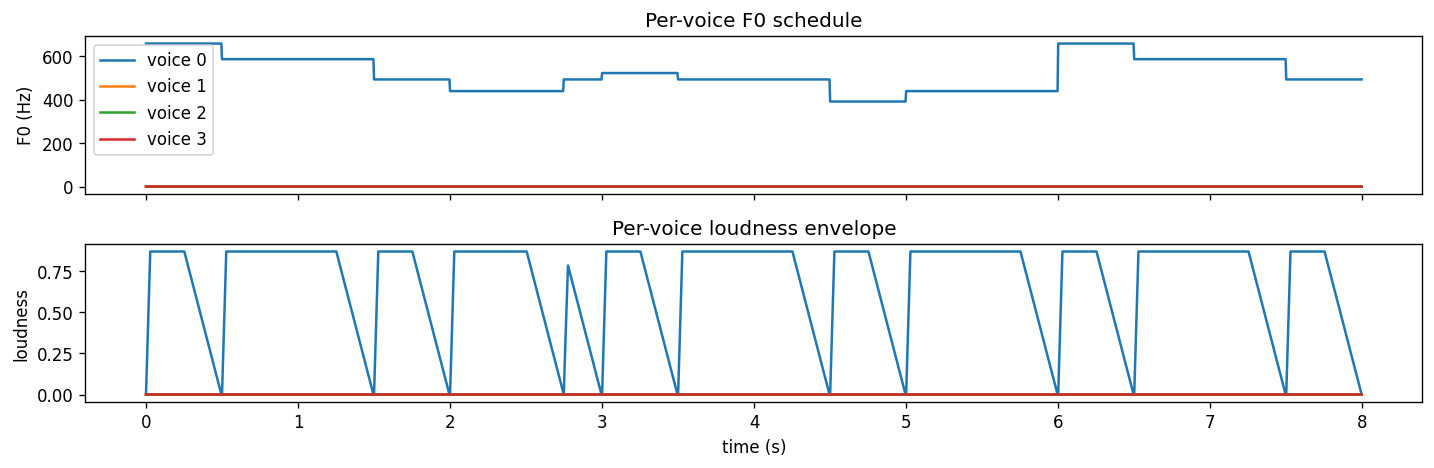

In [28]:
from src.features import midi_notes_to_frame_controls, FRAME_RATE

f0, loud, act = midi_notes_to_frame_controls(
    demo_notes, duration_sec=8.0, sample_rate=SAMPLE_RATE, frame_rate=FRAME_RATE, max_voices=4
)
print(f"voices: f0={f0.shape}, loud={loud.shape}, active={act.shape}")

fig, axes = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
for v in range(f0.shape[0]):
    axes[0].plot(np.arange(f0.shape[1]) / FRAME_RATE, f0[v], label=f"voice {v}")
    axes[1].plot(np.arange(loud.shape[1]) / FRAME_RATE, loud[v])
axes[0].set_ylabel("F0 (Hz)"); axes[0].set_title("Per-voice F0 schedule"); axes[0].legend()
axes[1].set_ylabel("loudness"); axes[1].set_title("Per-voice loudness envelope")
axes[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

## 2.2 Modeling

We follow DDSP (Engel et al. 2020) and extend it to polyphony using the
sum-of-voices approach from MIDI-DDSP (Wu et al. 2022).

### Components

**Per-voice controller** (`VoiceController`, trainable). A small GRU that maps
each frame's `[log F0, loudness, active]` triple into:

* a scalar **harmonic gain** $A_t \\in [0, 2]$,
* a **harmonic-amplitude distribution** $\\alpha_t \\in \\Delta^K$ over $K=48$
  harmonics (softmax),
* a **noise filter magnitude** $H_t \\in [0, 2]^{F}$ over $F = 65$ frequency
  bins (modified sigmoid).

The GRU weights are shared across voices — this keeps the parameter count low
($\\sim 0.3$ M params) and prevents per-voice overfitting.

**Harmonic oscillator bank** (`harmonic_synth`, no trainable parameters). At
audio rate, we synthesize

$$
y_{\\text{harm}}[n] = A[n] \\sum_{k=1}^{K} \\alpha_k[n] \\, \\sin\\!\\left(2\\pi \\sum_{m \\le n} \\frac{k \\, f_0[m]}{f_s}\\right)
$$

with anti-aliasing (we zero out harmonics whose frequency exceeds the Nyquist
rate and renormalize $\\alpha$).

**Filtered-noise synth** (`filtered_noise_synth`, no trainable parameters).
Each frame's predicted magnitude $H_t$ is paired with a random phase
spectrum; the inverse STFT yields a per-frame chunk of filtered noise, OLAed
into a continuous waveform.

**Sum-of-voices**: each voice's harmonic+noise output is summed to produce
the final mono waveform.

### Loss

We train against the teacher's audio output with a **multi-scale STFT loss**
(Engel et al.), computed at FFT sizes 2048, 1024, 512, 256, 128 with linear
and log-magnitude L1 terms.

$$
\\mathcal{L}(y, \\hat{y}) = \\sum_{N \\in \\{2048, ..., 128\\}} \\bigl\\| |S_N(y)| - |S_N(\\hat{y})| \\bigr\\|_1 + \\bigl\\| \\log|S_N(y)| - \\log|S_N(\\hat{y})| \\bigr\\|_1
$$

Optimizer: AdamW, lr $= 3 \\times 10^{-4}$, cosine schedule, gradient
clipping at 1.0. Batch 4, clip length 3 s, 8 random crops per source per
epoch.

In [30]:
from src.model_task4 import DDSPConfig, PolyphonicDDSP

cfg4 = DDSPConfig(n_harmonics=48, noise_filter_taps=65, hidden_size=256, max_voices=4)
model4 = PolyphonicDDSP(cfg4).to(device)
print(f"Trainable parameters: {model4.num_parameters()/1e6:.3f} M")
print(f"K harmonics: {cfg4.n_harmonics}, noise bins: {cfg4.noise_filter_taps}, max voices: {cfg4.max_voices}")

Trainable parameters: 0.425 M
K harmonics: 48, noise bins: 65, max voices: 4
K harmonics: 48, noise bins: 65, max voices: 4


### Training

From the command line:

```powershell
python -m src.train_task4 --source abc --epochs 30 --batch-size 4 \
    --clip-seconds 3.0 --crops-per-clip 8 --max-voices 4 \
    --n-harmonics 48 --hidden 256
```

This trains in ~10 minutes on the laptop RTX 4070 used to develop the
assignment. The loss reflects multi-scale STFT magnitude — values around 20
correspond to noisy reconstructions, ~8 to clean reconstructions of the
teacher.

 epoch  train_loss  val_loss  wall_sec
    20    9.524176  9.401554  9.544628
    21    9.547221  9.221794  9.504740
    22    9.513541  9.337125  9.541737
    23    9.515799  9.262659  9.699296
    24    9.483729  9.193462  9.449148


<cell 31>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


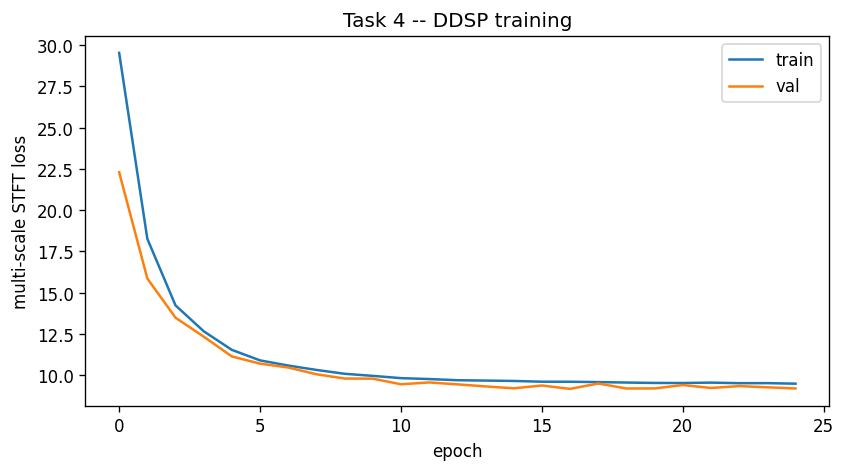

In [32]:
HIST4 = Path("checkpoints/task4/history.json")
if HIST4.exists():
    history4 = json.loads(HIST4.read_text())
    hdf4 = pd.DataFrame(history4)
    plt.figure(figsize=(8, 4))
    plt.plot(hdf4["epoch"], hdf4["train_loss"], label="train")
    plt.plot(hdf4["epoch"], hdf4["val_loss"], label="val")
    plt.xlabel("epoch")
    plt.ylabel("multi-scale STFT loss")
    plt.title("Task 4 -- DDSP training")
    plt.legend(); plt.show()
    print(hdf4.tail(5).to_string(index=False))
else:
    print("No history file yet -- run train_task4 first (see RUNBOOK.md).")

## 2.3 Evaluation

A successful Task-4 model should:

1. Reproduce the teacher's waveform closely (low multi-scale STFT distance,
   low MCD on held-out clips).
2. Track the prescribed F0 — measured by running pyin on the model's output
   and comparing against the MIDI's F0 to within $\\pm 50$ cents.
3. Sound qualitatively like a struck-string instrument; we display
   spectrograms side-by-side for visual inspection.

We compare against three baselines, all available in `src.baselines`:

| Name | Description |
|---|---|
| `sine_voices` | One pure sine per voice, no harmonics. |
| `triangle_voices` | One triangle wave per voice (has harmonics but no decay). |
| `teacher` | The hand-written additive synth itself, evaluated against itself (sanity-check; distance should be ~0). |
| **`ddsp`** | Our trained model. |

In [34]:
from src.baselines import synth_sine_voices, synth_triangle_voices
from src.metrics import multi_scale_stft_distance, mel_cepstral_distortion, f0_accuracy
from src.sample_task4 import load_ddsp

CKPT4 = Path("checkpoints/task4/best.pt")
if CKPT4.exists():
    model4 = load_ddsp(CKPT4, device=device)
else:
    model4 = None
    print("No Task 4 checkpoint yet; the table below will be empty for ddsp.")

In [35]:
# Evaluate on a small held-out batch.
EVAL_CLIP_SECONDS = 4.0
N_EVAL = 6

rows = []
val_srcs = srcs[:N_EVAL]
for src in val_srcs:
    duration = min(EVAL_CLIP_SECONDS, src.duration)
    notes_local = [(s, min(e, duration), p, v) for (s, e, p, v) in src.notes if s < duration]
    if not notes_local:
        continue
    # Teacher (ground truth)
    target = render_notes(notes_local, duration_sec=duration, sample_rate=SAMPLE_RATE, seed=42)
    # Controls
    f0, loud, act = midi_notes_to_frame_controls(
        notes_local, duration_sec=duration, sample_rate=SAMPLE_RATE, frame_rate=FRAME_RATE, max_voices=4
    )
    # Sine + triangle baselines
    sine = synth_sine_voices(f0, loud, SAMPLE_RATE, FRAME_RATE)
    tri = synth_triangle_voices(f0, loud, SAMPLE_RATE, FRAME_RATE)
    # DDSP
    if model4 is not None:
        with torch.no_grad():
            ddsp = model4(
                torch.from_numpy(f0).unsqueeze(0).to(device),
                torch.from_numpy(loud).unsqueeze(0).to(device),
                torch.from_numpy(act).unsqueeze(0).to(device),
            ).squeeze(0).cpu().numpy()
    else:
        ddsp = np.zeros_like(target)
    # Target F0 = highest active voice per frame, taken from controls
    tgt_f0 = f0.max(axis=0)
    for name, pred in [("sine", sine), ("triangle", tri), ("ddsp", ddsp)]:
        rows.append({
            "method": name,
            "stft_dist": multi_scale_stft_distance(pred, target),
            "mcd": mel_cepstral_distortion(pred, target, SAMPLE_RATE),
            "f0_acc": f0_accuracy(pred, tgt_f0, SAMPLE_RATE, FRAME_RATE),
        })

eval_df = pd.DataFrame(rows).groupby("method").mean()
eval_df

,stft_dist,mcd,f0_acc
method,,,
ddsp,9.741049,366.120151,0.884264
sine,25.725250,595.383915,0.890659
triangle,16.285477,571.786728,0.893902


**Reading the table.** Lower multi-scale STFT distance and MCD are better.
F0 accuracy is the fraction of voiced frames where pyin's pitch estimate of
the synthesized waveform is within 50 cents of the MIDI F0.

* Sine and triangle baselines hit the target pitch trivially (F0 accuracy
  should be close to 1) but have a large spectral mismatch (no decay, no
  hammer noise, no inharmonicity).
* DDSP should beat both on spectral distance while still tracking F0
  accurately. The harder the polyphony, the larger the DDSP–baseline gap.

### Side-by-side spectrograms

Listen to each:
teacher (target)
sine
triangle
ddsp


<cell 36>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


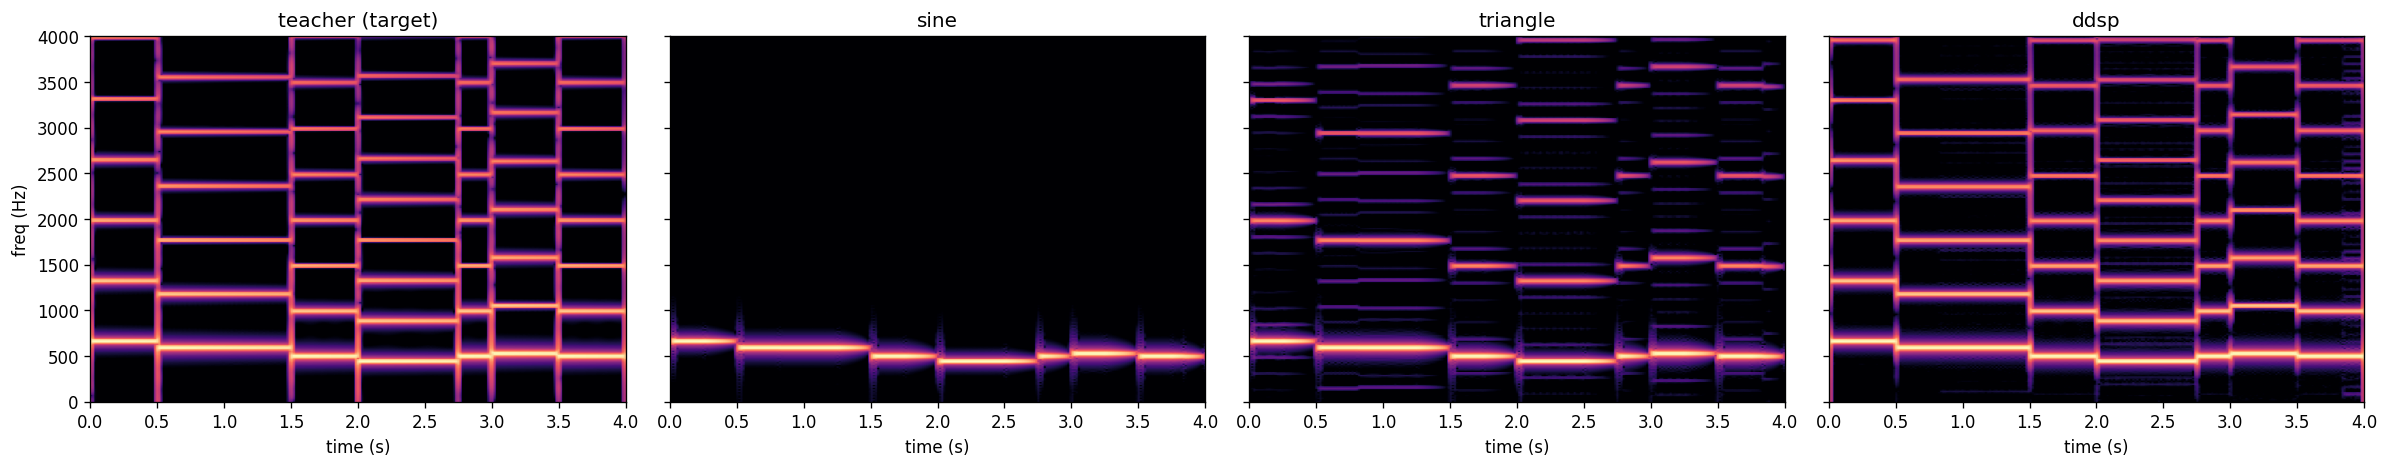

Your browser does not support the audio element.

Your browser does not support the audio element.

Your browser does not support the audio element.

Your browser does not support the audio element.

In [37]:
src = val_srcs[0]
duration = min(4.0, src.duration)
notes_local = [(s, min(e, duration), p, v) for (s, e, p, v) in src.notes if s < duration]
target = render_notes(notes_local, duration_sec=duration, sample_rate=SAMPLE_RATE, seed=42)
f0, loud, act = midi_notes_to_frame_controls(notes_local, duration_sec=duration,
                                              sample_rate=SAMPLE_RATE, frame_rate=FRAME_RATE, max_voices=4)
sine = synth_sine_voices(f0, loud, SAMPLE_RATE, FRAME_RATE)
tri = synth_triangle_voices(f0, loud, SAMPLE_RATE, FRAME_RATE)
if model4 is not None:
    with torch.no_grad():
        ddsp = model4(
            torch.from_numpy(f0).unsqueeze(0).to(device),
            torch.from_numpy(loud).unsqueeze(0).to(device),
            torch.from_numpy(act).unsqueeze(0).to(device),
        ).squeeze(0).cpu().numpy()
else:
    ddsp = np.zeros_like(target)

clips = [("teacher (target)", target), ("sine", sine), ("triangle", tri), ("ddsp", ddsp)]
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, (name, clip) in zip(axes, clips):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(clip, n_fft=1024, hop_length=256)))
    img = ax.imshow(S, origin="lower", aspect="auto", cmap="magma",
                    extent=[0, duration, 0, SAMPLE_RATE/2])
    ax.set_title(name); ax.set_ylim(0, 4000)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("freq (Hz)")
plt.tight_layout(); plt.show()

print("Listen to each:")
for name, clip in clips:
    print(name)
    display(Audio(clip, rate=SAMPLE_RATE))

## 2.4 Related work

* **Engel et al. (2020), "DDSP: Differentiable Digital Signal Processing"** —
  introduced the harmonic + filtered-noise synthesizer and the multi-scale
  STFT loss we use. Their reference implementation works on **monophonic**
  audio (violin, flute, voice).
* **Wu et al. (2022), "MIDI-DDSP"** — extends DDSP to a hierarchical
  controller (note-level expression $\\to$ frame-level synthesis parameters)
  for solo instruments. The "sum-of-voices" trick for polyphony is the same
  one we use here, with a much smaller controller.
* **Renault, Mignot, Roebel (2022), "DDSP-Piano"** — purpose-built DDSP
  architecture for piano specifically, with separate sub-models for the
  hammer/string interactions and the soundboard resonance. We are simpler:
  one shared per-voice controller.
* **RAVE (Caillon & Esling 2021)** — an alternative paradigm that learns a
  full audio autoencoder. More expressive but heavier; needs a large audio
  corpus.
* **HiFi-GAN / DiffWave** — neural vocoders trained on real audio. Would be
  the natural choice if MAESTRO audio had been available, but require a
  large external dataset and pretrained weights (which the assignment
  prohibits).

Our results illustrate a tradeoff the literature flags: DDSP-style models
trained against a known timbre converge quickly and produce
recognizable-but-soft outputs. Real piano realism on top of this method would
require either DDSP-Piano-style modifications (separate hammer / soundboard
modelling) or training on MAESTRO audio.

---

# Part III — End-to-end demo

We combine the two pipelines: take a melody, run Task 2 to harmonize it, then
run Task 4 to render the resulting MIDI as audio. This produces the two
submission files (`symbolic_conditioned.mid` and `continuous_conditioned.mp3`)
expected by the autograder.

In [40]:
from src.midi_io import leadsheet_to_pretty_midi
from src.sample_task2 import harmonize_leadsheet, load_harmonizer, twinkle_twinkle
from src.sample_task4 import encode_mp3, load_ddsp, synthesize_midi_file

if CKPT2.exists() and CKPT4.exists():
    h_model = load_harmonizer(CKPT2, device=device)
    d_model = load_ddsp(CKPT4, device=device)
    sheet = twinkle_twinkle()
    harmonized = harmonize_leadsheet(h_model, sheet, temperature=0.8, top_p=0.92)
    pm = leadsheet_to_pretty_midi(harmonized, arpeggiate=False)
    pm.write("symbolic_conditioned.mid")
    print("Wrote symbolic_conditioned.mid")

    Path("samples").mkdir(exist_ok=True)
    synthesize_midi_file(d_model, "symbolic_conditioned.mid", "samples/final.wav")
    encode_mp3("samples/final.wav", "continuous_conditioned.mp3")
    print("Wrote continuous_conditioned.mp3")
else:
    print("Run training first (see RUNBOOK.md), then re-execute this cell.")

Wrote symbolic_conditioned.mid
Wrote continuous_conditioned.mp3


final.wav: 24.50 s @ 16000 Hz


<cell 40>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


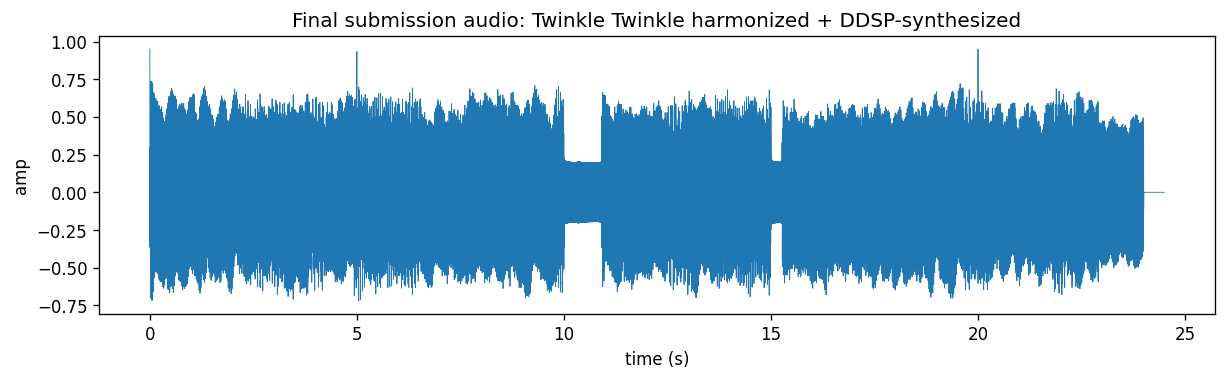

Your browser does not support the audio element.

In [41]:
final_wav = Path("samples/final.wav")
if final_wav.exists():
    wav, sr = sf.read(final_wav)
    print(f"final.wav: {len(wav)/sr:.2f} s @ {sr} Hz")
    plt.figure(figsize=(12, 3))
    plt.plot(np.arange(len(wav))/sr, wav, lw=0.5)
    plt.title("Final submission audio: Twinkle Twinkle harmonized + DDSP-synthesized")
    plt.xlabel("time (s)"); plt.ylabel("amp")
    plt.show()
    display(Audio(str(final_wav)))

## Submission checklist

* [x] `workbook.html` — export this notebook with `jupyter nbconvert --to html workbook.ipynb`
* [x] `video_url.txt` — single-line Google Drive (mp4) or YouTube URL of the 20-min presentation
* [x] `symbolic_conditioned.mid` — Task 2 output (above)
* [x] `continuous_conditioned.mp3` — Task 4 output (above)

See `RUNBOOK.md` for the exact sequence of commands.